# Validate linear summation (metamodel vs dynamic)

Compare offshore-driven **dynamic SnapWave** to the **reconstructed metamodel**
(spectral mode: WHACS partitions `0`–`3` per goal, wavespectra linear sum).

Bulk output is configured in `Samoa.json` → `metamodel.reconstruction.variables`
(HyGloW name → wavespectra stat). Set `save_spectra: true` to cache summed spectra
for notebook 11.

Comparison uses `hs`, `tp`, `dir`, and `spr` when both datasets contain them
(`val.resolve_comparison_variables`).

**Prerequisites:** fitted models (06), dynamic run (08). Use `recompute=True` after refitting.

In [1]:
import matplotlib.pyplot as plt
import xarray as xr
from utils.config import SIMULATIONS, resolve
from utils.evaluation import validation as val
from utils.model import metamodel as mm

## Configuration

In [2]:
period = "2020-01"
offshore_name = "WHACS"
mda_n = 450  # must match a fitted mda_candidates entry
pca_variance = 0.99  # or 0.99, or {"hs": 0.99, etc}

# Site subset — isobath depth, mesh polygon, buoy id, or umbrella
sites = ["buoy_Aunuu_Buoy"]  # e.g. "10m", "buoy", ["10m", "buoy_Apolima_Buoy"]

# Metrics to compare (subset used when missing from either dataset)
compare_variables = ["hs", "tp", "dir", "spr"]

dynamic_path = (
    # resolve(SIMULATIONS["dynamic_cases"]) / f"Dynamic_Cases_{offshore_name}_2020.nc"
    "outputs/SnapWave_Dynamic_202001.nc"
)

print(f"period       : {period}")
print(f"mda_n        : {mda_n}")
print(f"sites        : {sites}")
print(f"compare vars : {compare_variables}")
print(f"dynamic path : {dynamic_path}")

period       : 2020-01
mda_n        : 450
sites        : ['buoy_Aunuu_Buoy']
compare vars : ['hs', 'tp', 'dir', 'spr']
dynamic path : outputs/SnapWave_Dynamic_202001.nc


## 1 · Check models

In [3]:
mm.require_models_all(mda_n, pca_variance=pca_variance)
print(f"common model sites: {len(mm.common_model_sites())}")

common model sites: 4087


## 2 · Reconstruct metamodel (spectral)

In [4]:
metamodel = mm.reconstruct(
    period,
    mda_n,
    spectral=True,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)
metamodel

INFO:ExactGPInterpolation:Preprocessing dataset for prediction
INFO:ExactGPInterpolation:Checking for NaNs in subset data
INFO:ExactGPInterpolation:Preprocessing subset data
INFO:ExactGPInterpolation:Normalizing subset data
INFO:ExactGPInterpolation:Proposed max custom scaler for spr is lower than datapoint
INFO:ExactGPInterpolation:Subset data preprocessed successfully
INFO:ExactGPInterpolation:Predicting target variable: hs__PC1
INFO:ExactGPInterpolation:Predicting target variable: hs__PC2
INFO:ExactGPInterpolation:Predicting target variable: hs__PC3
INFO:ExactGPInterpolation:Predicting target variable: hs__PC4
INFO:ExactGPInterpolation:Predicting target variable: hs__PC5
INFO:ExactGPInterpolation:Predicting target variable: hs__PC6
INFO:ExactGPInterpolation:Predicting target variable: hs__PC7
INFO:ExactGPInterpolation:Predicting target variable: hs__PC8
INFO:ExactGPInterpolation:Predicting target variable: hs__PC9
INFO:ExactGPInterpolation:Predicting target variable: hs__PC10
INFO:E

<xarray.Dataset> Size: 27kB
Dimensions:         (time: 744, sites: 1)
Coordinates:
  * time            (time) datetime64[ns] 6kB 2020-01-01 ... 2020-01-31T23:00:00
  * sites           (sites) <U24 96B 'buoy_Aunuu_Buoy'
    site_source     (sites) <U7 28B 'buoy'
    site_label      (sites) <U5 20B 'waves'
    site_depth      (sites) float64 8B -55.0
    site_longitude  (sites) float64 8B -170.5
    site_latitude   (sites) float64 8B -14.27
Data variables:
    hs              (time, sites) float64 6kB 2.54 2.501 2.481 ... 1.499 1.518
    tp              (time, sites) float32 3kB 7.927 7.768 8.095 ... 15.8 15.78
    dir             (time, sites) float64 6kB 291.7 279.4 273.1 ... 10.59 11.13
    spr             (time, sites) float64 6kB 57.76 60.22 59.37 ... 60.93 61.73

## 3 · Load dynamic reference

In [5]:
dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids).load()
dynamic

<xarray.Dataset> Size: 18kB
Dimensions:         (time: 744, sites: 1)
Coordinates:
  * time            (time) datetime64[ns] 6kB 2020-01-01 ... 2020-01-31T23:00:00
  * sites           (sites) <U24 96B 'buoy_Aunuu_Buoy'
    site_source     (sites) <U7 28B 'buoy'
    site_label      (sites) <U5 20B 'waves'
    site_depth      (sites) float64 8B -55.0
    site_longitude  (sites) float64 8B -170.5
    site_latitude   (sites) float64 8B -14.27
Data variables:
    hs              (time, sites) float32 3kB 2.574 2.543 2.542 ... 1.368 1.339
    tp              (time, sites) float32 3kB 8.661 8.855 9.032 ... 15.4 15.46
    dir             (time, sites) float32 3kB 274.2 267.6 265.2 ... 42.56 41.28
    spr             (time, sites) float32 3kB 49.61 50.28 50.57 ... 47.15 47.44
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output

## 4 · Compare

In [6]:
variables = val.resolve_comparison_variables(
    metamodel,
    dynamic,
    variables=compare_variables,
)
print(f"Comparing: {variables}")

result = val.compare(
    metamodel,
    dynamic,
    variables=variables,
    estimate_label="Linear summation",
    reference_label="Dynamic SnapWave",
    pca_variance=pca_variance,
)
result.metrics

Comparing: ['hs', 'tp', 'dir', 'spr']


,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label
0,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,hs,Hs,744,0.189828,0.280477,0.670637,Linear summation,Dynamic SnapWave
1,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,tp,Tp,744,-1.585275,2.801014,0.052976,Linear summation,Dynamic SnapWave
2,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,dir,Dir,744,-1.476219,30.674881,0.796211,Linear summation,Dynamic SnapWave
3,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,spr,Spr,744,10.273321,13.250308,-0.692352,Linear summation,Dynamic SnapWave


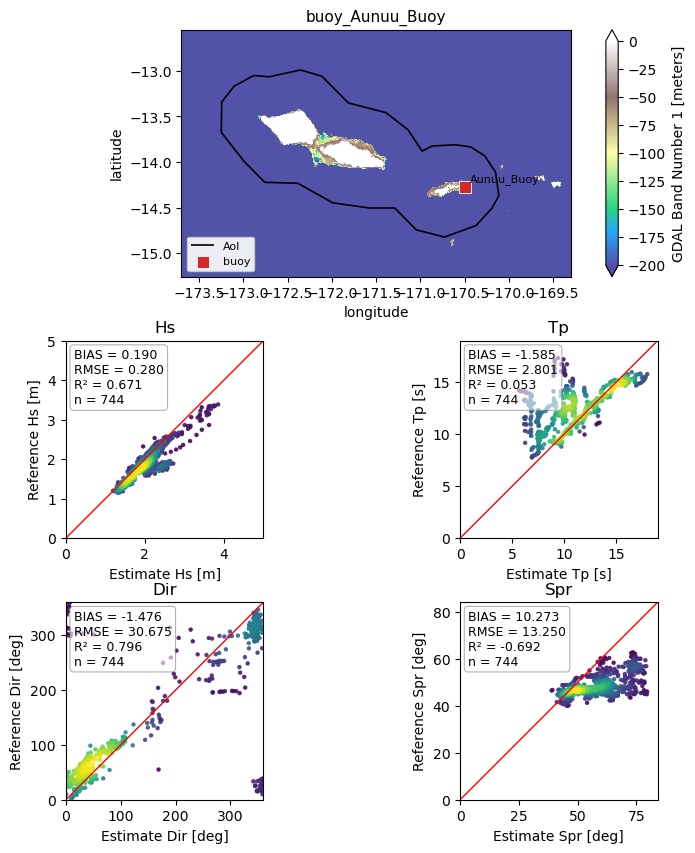

In [7]:
result.plot_all(variables=variables)
plt.show()